In [27]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

# EDA

In [28]:
INPUT_FILE_PATH = "./water_potability.csv"
df = pd.read_csv(INPUT_FILE_PATH)
display(df.head())

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


In [29]:
df.dtypes

ph                 float64
Hardness           float64
Solids             float64
Chloramines        float64
Sulfate            float64
Conductivity       float64
Organic_carbon     float64
Trihalomethanes    float64
Turbidity          float64
Potability           int64
dtype: object

In [30]:
df.describe()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
count,2785.000000,3276.000000,3276.000000,3276.000000,2495.000000,3276.000000,3276.000000,3114.000000,3276.000000,3276.000000
mean,7.080795,196.369496,22014.092526,7.122277,333.775777,426.205111,14.284970,66.396293,3.966786,0.390110
std,1.594320,32.879761,8768.570828,1.583085,41.416840,80.824064,3.308162,16.175008,0.780382,0.487849
min,0.000000,47.432000,320.942611,0.352000,129.000000,181.483754,2.200000,0.738000,1.450000,0.000000
25%,6.093092,176.850538,15666.690297,6.127421,307.699498,365.734414,12.065801,55.844536,3.439711,0.000000
50%,7.036752,196.967627,20927.833607,7.130299,333.073546,421.884968,14.218338,66.622485,3.955028,0.000000
75%,8.062066,216.667456,27332.762127,8.114887,359.950170,481.792304,16.557652,77.337473,4.500320,1.000000
max,14.000000,323.124000,61227.196008,13.127000,481.030642,753.342620,28.300000,124.000000,6.739000,1.000000


In [31]:
df.isna().sum()

ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

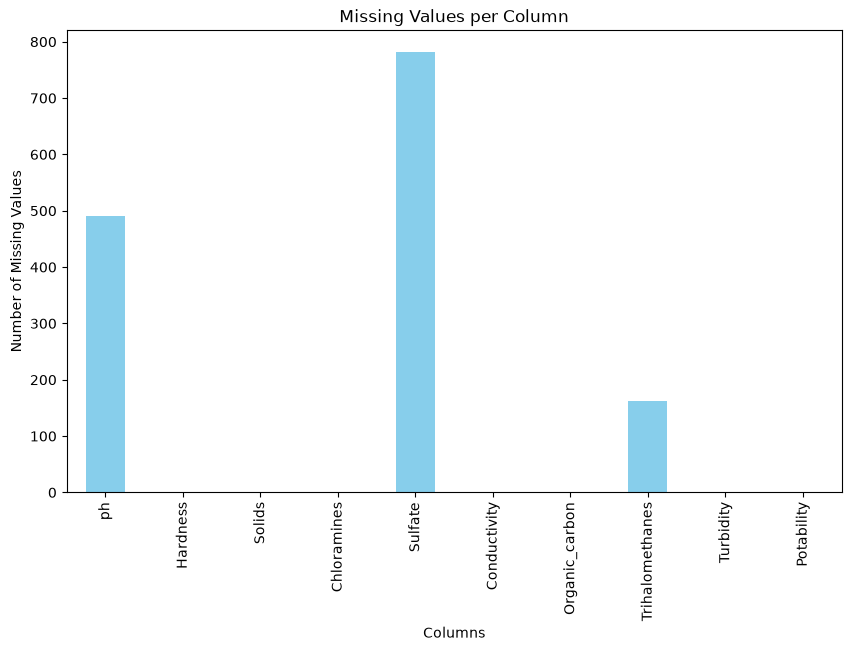

In [32]:
df.isna().sum().plot(kind="bar", figsize=(10, 6), color="skyblue")
plt.title("Missing Values per Column")
plt.ylabel("Number of Missing Values")
plt.xlabel("Columns")
plt.show()

### ph column

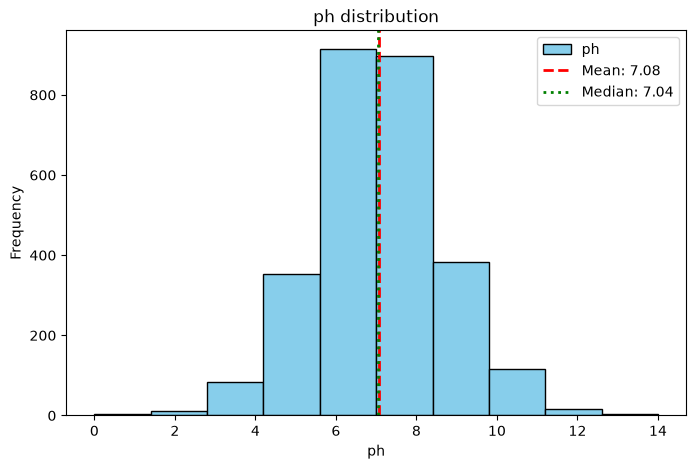

In [33]:
def plot_frequency(col: str):
    mean_val = df[col].mean()
    median_val = df[col].median()

    ax = df[col].plot.hist(bins=10, edgecolor='black', color='skyblue', figsize=(8, 5))

    ax.axvline(mean_val, color='red', linestyle='dashed', linewidth=2, label=f'Mean: {mean_val:.2f}')
    ax.axvline(median_val, color='green', linestyle='dotted', linewidth=2, label=f'Median: {median_val:.2f}')

    plt.title(f'{col} distribution')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.legend()

    plt.show()

plot_frequency("ph")

### Sulfate column

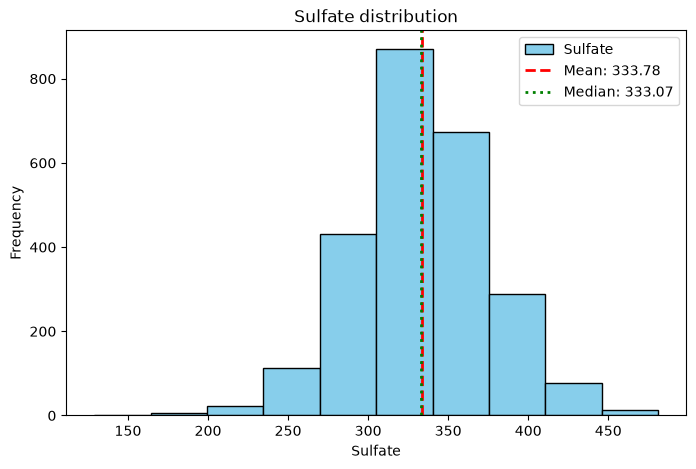

In [34]:
plot_frequency("Sulfate")

### Trihalomethanes column

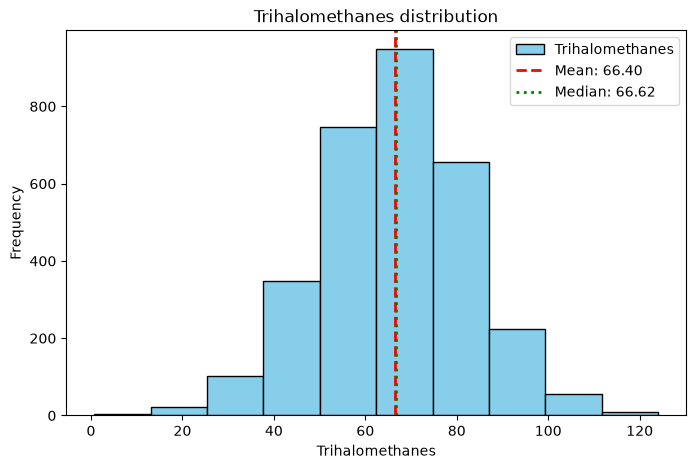

In [35]:
plot_frequency("Trihalomethanes")

In [36]:
df["ph"] = df["ph"].fillna(df["ph"].mean())

### Outliers

In [37]:
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_mask = (df < lower_bound) | (df > upper_bound)
print("Outliers found:")
print(outliers_mask.sum())

Outliers found:
ph                 142
Hardness            83
Solids              47
Chloramines         61
Sulfate             41
Conductivity        11
Organic_carbon      25
Trihalomethanes     33
Turbidity           19
Potability           0
dtype: int64


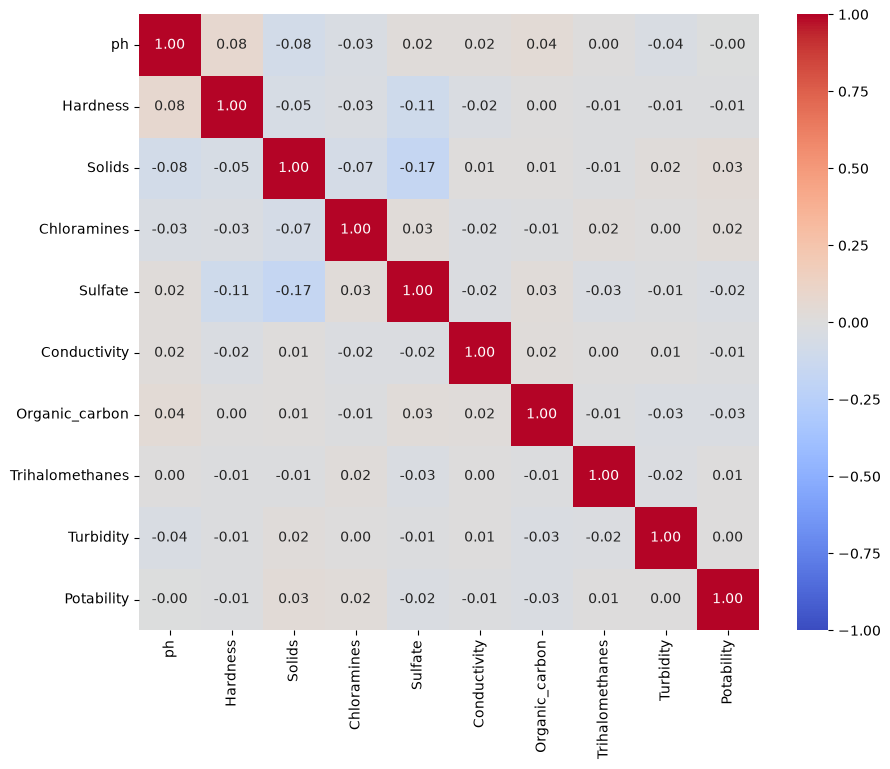

In [38]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.show()

In [39]:
print(df.skew())
print(f"Number of highly skewed columns: {(df.skew().abs() > 1).sum()}")

ph                 0.027796
Hardness          -0.039342
Solids             0.621634
Chloramines       -0.012098
Sulfate           -0.035947
Conductivity       0.264490
Organic_carbon     0.025533
Trihalomethanes   -0.083031
Turbidity         -0.007817
Potability         0.450784
dtype: float64
Number of highly skewed columns: 0


In [40]:
df["Potability"].value_counts()

Potability
0    1998
1    1278
Name: count, dtype: int64

In [41]:
df.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,7.080795,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


In [42]:
from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
df[numeric_cols] = scaler.fit_transform(df[numeric_cols])

In [43]:
df.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,0.000000,0.198981,-0.011702,0.085492,0.678324,1.227178,-0.854560,0.947683,-0.935210,0.0
1,-2.113014,-1.696382,-0.196962,-0.249088,NaN,1.473406,0.214093,-0.478921,0.514449,0.0
2,0.639503,0.684850,-0.087287,1.079558,NaN,-0.028251,0.590024,-0.009417,-0.847715,0.0
3,0.776180,0.437145,0.093483,0.467446,0.455737,-0.505079,0.939076,1.568850,0.635242,0.0
4,1.263161,-0.398477,-0.252771,-0.293690,-0.438995,-0.202262,-0.592197,-1.610971,0.113188,0.0


### Save

In [44]:
df.to_csv("./cleaned_water_potability.csv")

# Hypothesis

In [45]:
from scipy import stats

t_stat, p_value = stats.ttest_ind(df["ph"], df["Solids"])
t_stat, p_value

(np.float64(-4.476932191647956), np.float64(7.700634902878802e-06))

In [46]:
if p_value < 0.05:
    print("p < 0.05; Reject the null hypothesis at 5% sig level.")
else:
    print("p > 0.05; Failed to reject the null hypothesis.")

p < 0.05; Reject the null hypothesis at 5% sig level.


# Next step

Test more hypothesis. May be.

# Quality of data

Some way bad because of missing values.

# Key findings

ph and solid are irrelevant.